# Cross Environment Analysis - E1 to E4

This notebook brings the four controlled environments together into a single analysis. Each environment was trained and evaluated on its own in the `model_train` notebooks, and each one saved a small comparison table of the four models. This notebook loads those four tables and builds the combined view that the study was designed around.

The four environments share the same 100 validated files and the same fixed 287 opcode vocabulary. This means the only thing that changes between them is the two controlled factors, so the results can be compared directly. The two factors are,

- **JIT compilation** - on in E1 and E3, off (`-Xint`) in E2 and E4.
- **Obfuscation** - clean JARs in E1 and E2, ProGuard obfuscated JARs in E3 and E4.


The purpose here is not to train anything new. All the models are already trained and evaluated. This notebook only reads the saved results and turns them into the comparison table and the plots that go into the report.


## Setup the imports and paths

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# The order is kept fixed everywhere in this notebook so every table and plot reads 
# E1 -> E2 -> E3 -> E4 the same way
ENVIRONMENTS = {
    "E1": "JIT, clean",
    "E2": "No-JIT, clean",
    "E3": "JIT, obfuscated",
    "E4": "No-JIT, obfuscated",
}
ENV_ORDER = list(ENVIRONMENTS.keys())

ENV_DIRS = {
    "E1": "data",
    "E2": "data-e2",
    "E3": "data-e3",
    "E4": "data-e4",
}

# Root folder that holds the per environment analysis folders
ANALYSIS_ROOT = "../sandbox"

# Model display order - best to worst on the baseline kept fixed so colours and
# rows line up across every plot instead of being re sort per environment
MODEL_ORDER = [
    "Isolation Forest",
    "Local Outlier Factor",
    "One-Class SVM",
    "Elliptic Envelope",
]

# Where the assembled outputs (combined table + figures) get written
OUTPUT_DIR = os.path.join(ANALYSIS_ROOT, "cross_env_results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Loading the Four Environment Result Tables

Each `model_train` notebook saved a comparison table for its environment into that environment's `models/` folder. Those tables all have the same columns (`Model`, `Mean FPR`, `Std`, `Min FPR`, `Max FPR`), one row per model.


In [ ]:
def load_environment_table(env_code):
    # Build the path to this environment's models folder
    models_dir = os.path.join(ANALYSIS_ROOT, ENV_DIRS[env_code], "models")

    model_compare = ["model_comparison_approach_1.csv"]

    for name in model_compare:
        path = os.path.join(models_dir, name)

        if os.path.exists(path):
            table = pd.read_csv(path)
            table["Environment"] = env_code
            table["Config"] = ENVIRONMENTS[env_code]
            return table

    # If there is an file not found error
    raise FileNotFoundError(
        f"No comparison table found for {env_code} in {models_dir}. "
        f"Looked for: {model_compare}"
    )

# Load all four and stack them into one long table
env_tables = [load_environment_table(code) for code in ENV_ORDER]
all_results = pd.concat(env_tables, ignore_index=True)

print(f"Loaded {len(env_tables)} environments - {len(all_results)} rows total\n")
print(all_results[["Environment", "Config", "Model", "Mean FPR", "Std"]].to_string(index = False))


Loaded 4 environments - 16 rows total
Environment             Config                Model  Mean FPR      Std
         E1         JIT, clean     Isolation Forest      0.06 0.073485
         E1         JIT, clean Local Outlier Factor      0.11 0.086023
         E1         JIT, clean        One-Class SVM      0.44 0.106771
         E1         JIT, clean    Elliptic Envelope      0.89 0.073485
         E2      No-JIT, clean     Isolation Forest      0.08 0.081240
         E2      No-JIT, clean Local Outlier Factor      0.08 0.050990
         E2      No-JIT, clean        One-Class SVM      0.43 0.201494
         E2      No-JIT, clean    Elliptic Envelope      0.93 0.060000
         E3    JIT, obfuscated     Isolation Forest      0.07 0.067823
         E3    JIT, obfuscated Local Outlier Factor      0.15 0.070711
         E3    JIT, obfuscated        One-Class SVM      0.42 0.180555
         E3    JIT, obfuscated    Elliptic Envelope      0.91 0.037417
         E4 No-JIT, obfuscated     Isol

## The Four Environment Comparison Table

This is the core result of the whole study. The long table above is just loading the all data into one table so that each row is a model and each column is an environment, with the mean false positive rate in each cell. This means the effect of changing JIT or obfuscation can be read straight across a single row, which is exactly the comparison the four environment design was built to make.

The rows are ordered from the strongest model on the baseline to the weakest, so the table reads top to bottom in order of usefulness. A low value is better, because every test file is benign, so any flagged file is a false positive.


In [7]:
mean_fpr_table = all_results.pivot(
    index = "Model", columns = "Environment", values = "Mean FPR"
)

# Reorder rows and columns to the fixed order defined at the top
mean_fpr_table = mean_fpr_table.loc[MODEL_ORDER, ENV_ORDER]

print("Mean False Positive Rate across all four environments (lower is better)\n")
print(mean_fpr_table.to_string(float_format=lambda v: f"{v:.3f}"))

# Save the headline table so it can be dropped straight into the report
mean_fpr_table.to_csv(os.path.join(OUTPUT_DIR, "four_environment_mean_fpr.csv"))
print(f"\nSaved to {OUTPUT_DIR}/four_environment_mean_fpr.csv")


Mean False Positive Rate across all four environments (lower is better)

Environment             E1    E2    E3    E4
Model                                       
Isolation Forest     0.060 0.080 0.070 0.060
Local Outlier Factor 0.110 0.080 0.150 0.120
One-Class SVM        0.440 0.430 0.420 0.420
Elliptic Envelope    0.890 0.930 0.910 0.880

Saved to ../sandbox\cross_env_results/four_environment_mean_fpr.csv


## Table with Mean and Standard Deviation Together

The mean on its own does not show how stable each result is. On a dataset of 100 files with 5 fold cross validation there are only 20 files in each fold, so the fold to fold spread matters as much as the average. This table pairs each mean with its standard deviation in a single `mean +- std` string, so there is one table that have both numbers without needing two separate grids.

In [9]:
def mean_std_string(row):
    # Format one model+environment result as "mean +- std" for a compact combined table
    return f"{row['Mean FPR']:.3f} ± {row['Std']:.3f}"

all_results["mean_std"] = all_results.apply(mean_std_string, axis=1)

combined_table = all_results.pivot(
    index="Model", columns="Environment", values = "mean_std"
).loc[MODEL_ORDER, ENV_ORDER]

print("Mean ± Std False Positive Rate across all four environments\n")
print(combined_table.to_string())

combined_table.to_csv(os.path.join(OUTPUT_DIR, "four_environment_mean_std.csv"))

Mean ± Std False Positive Rate across all four environments

Environment                      E1             E2             E3             E4
Model                                                                           
Isolation Forest      0.060 ± 0.073  0.080 ± 0.081  0.070 ± 0.068  0.060 ± 0.073
Local Outlier Factor  0.110 ± 0.086  0.080 ± 0.051  0.150 ± 0.071  0.120 ± 0.068
One-Class SVM         0.440 ± 0.107  0.430 ± 0.201  0.420 ± 0.181  0.420 ± 0.121
Elliptic Envelope     0.890 ± 0.073  0.930 ± 0.060  0.910 ± 0.037  0.880 ± 0.093


## Grouped Bar Chart of All Models Across All Environments

The table gives the exact numbers but a grouped bar chart makes the overall shape easier to see at 1st glance. Each group of bars is one model, and the four bars inside a group are the four environments. The error bar on each bar is the standard deviation across the folds, so a tall error bar means the result deviated a lot between folds and cannot be fully trusted on its own.

The main thing to look for is whether each model keeps roughly the same height across its four bars. A model whose bars stay level across all four environments is one that does not care about JIT or obfuscation which is the robustness this study is testing for.


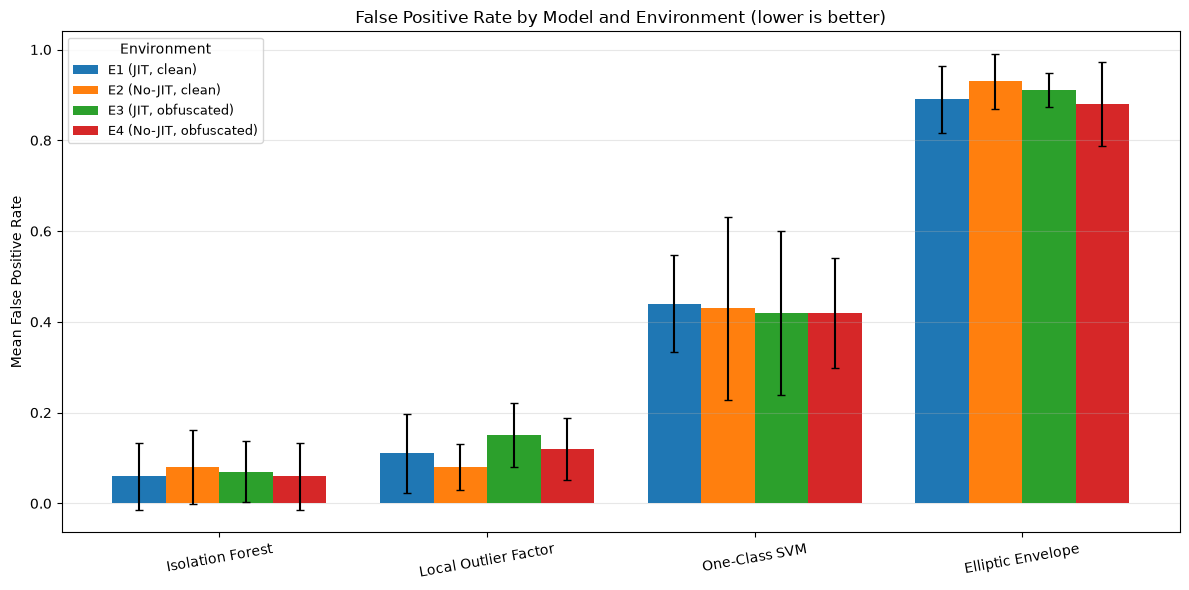

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(MODEL_ORDER)) # One group position per model
bar_width = 0.2

# Draw one set of bars per environment and offset side by side within each model group
for i, env in enumerate(ENV_ORDER):
    env_rows = all_results[all_results["Environment"] == env].set_index("Model").loc[MODEL_ORDER]
    ax.bar(
        x + i * bar_width,
        env_rows["Mean FPR"],
        bar_width,
        yerr = env_rows["Std"],
        capsize = 3,
        label = f"{env} ({ENVIRONMENTS[env]})",
    )

# Centre the model labels under each group of four bars
ax.set_xticks(x + 1.5 * bar_width)
ax.set_xticklabels(MODEL_ORDER, rotation = 10)

ax.set_ylabel("Mean False Positive Rate")
ax.set_title("False Positive Rate by Model and Environment (lower is better)")

ax.legend(title="Environment", fontsize=9)
ax.grid(axis = "y", alpha = 0.3)

plt.tight_layout()
plt.show()

## Heatmap of the Comparison Table

This is the same model by environment table drawn as a heatmap. The colour goes from green for a low false positive rate to red for a high one, so it is easy to see. The exact value is still printed inside each cell so nothing is lost.

This view makes two patterns obvious at once. Reading down a column shows how the models rank inside one environment, and reading across a row shows how one model holds up as the environment changes. A row that stays green all the way across is a model that generalises across every combination of JIT and obfuscation.


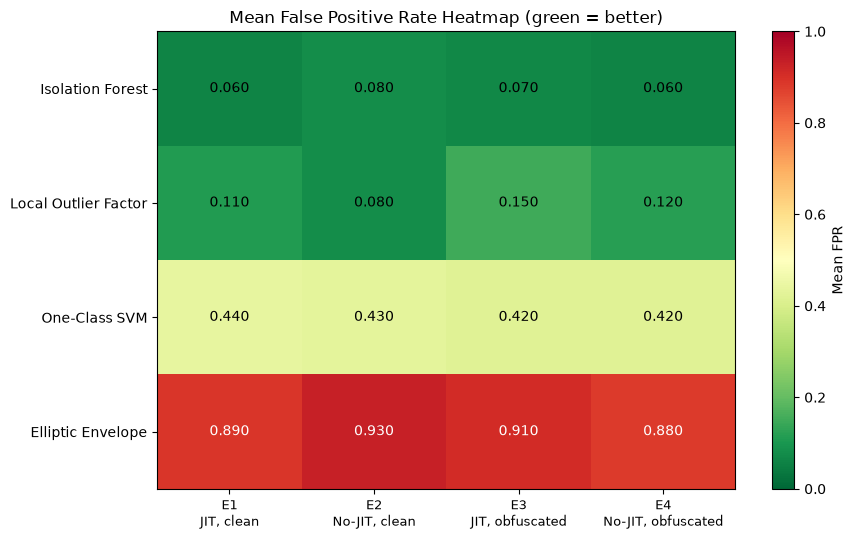

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))

# Red Yellow Green reversed so low FPR (good) is green and high FPR (bad) is red
heat = mean_fpr_table.values
im = ax.imshow(heat, cmap="RdYlGn_r", aspect="auto", vmin=0.0, vmax=1.0)

# Axis labels with the environment description under each code
ax.set_xticks(range(len(ENV_ORDER)))
ax.set_xticklabels([f"{e}\n{ENVIRONMENTS[e]}" for e in ENV_ORDER], fontsize=9)
ax.set_yticks(range(len(MODEL_ORDER)))
ax.set_yticklabels(MODEL_ORDER)

# Print the value inside each cell, in a colour that stays readable on the fill
for r in range(len(MODEL_ORDER)):
    for c in range(len(ENV_ORDER)):
        value = heat[r, c]
        text_colour = "white" if value > 0.6 else "black"
        ax.text(c, r, f"{value:.3f}", ha = "center", va = "center", color=text_colour)

ax.set_title("Mean False Positive Rate Heatmap (green = better)")
plt.colorbar(im, ax=ax, label="Mean FPR")

plt.tight_layout()
plt.show()

## The Isolation Forest Generalization Result

The Isolation Forest is the strongest model in every environment, so it need to have its own plot. This chart tracks its false positive rate across the four environments with the fold spread shown as an error band. The dashed line marks the 5% contamination level the model was told to expect, which is a natural reference point for what a good result looks like.

If the line stays roughly flat across all four environments it means the Isolation Forest models the benign baseline just as well whether JIT is on or off and whether the code is clean or obfuscated. That is a stronger result than any single environment number, because it says the detector does not depend on the two things an attacker could most easily change.

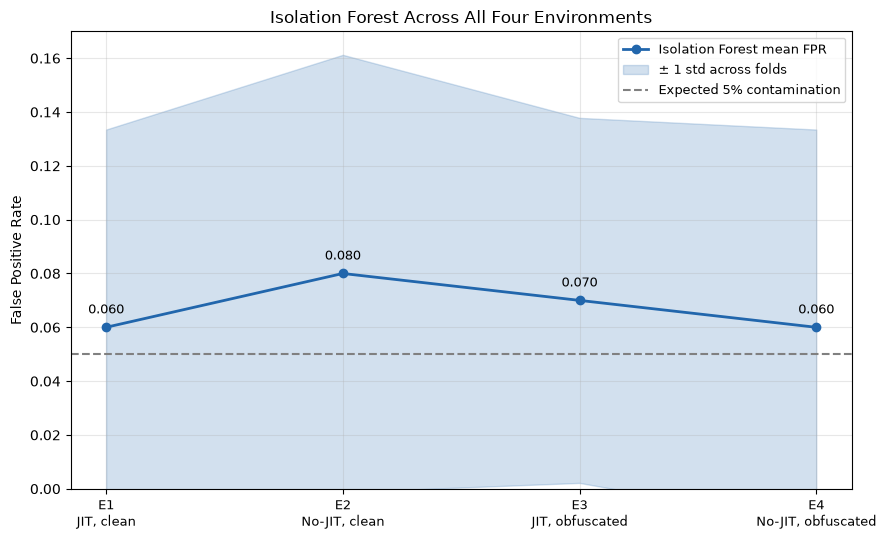

In [ ]:
iso_results = all_results[all_results["Model"] == "Isolation Forest"].set_index("Environment").loc[ENV_ORDER]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Mean line with the fold-to-fold standard deviation drawn as a shaded band
ax.plot(ENV_ORDER, iso_results["Mean FPR"], marker="o", linewidth = 2, 
        color = "#2166ac", label = "Isolation Forest mean FPR")

ax.fill_between(
    ENV_ORDER,
    iso_results["Mean FPR"] - iso_results["Std"],
    iso_results["Mean FPR"] + iso_results["Std"],
    alpha=0.2,
    color="#2166ac",
    label="± 1 std across folds",
)

# Reference line at the expected 5% contamiation level
ax.axhline(0.05, linestyle = "--", color = "gray", label = "Expected 5% contamination")

# Print each mean value next to its point
for env in ENV_ORDER:
    ax.annotate(
        f"{iso_results.loc[env, 'Mean FPR']:.3f}",
        (env, iso_results.loc[env, "Mean FPR"]),
        textcoords = "offset points",
        xytext = (0, 10),
        ha = "center",
        fontsize = 9,
    )

ax.set_xticks(range(len(ENV_ORDER)))
ax.set_xticklabels([f"{e}\n{ENVIRONMENTS[e]}" for e in ENV_ORDER], fontsize=9)
ax.set_ylabel("False Positive Rate")
ax.set_ylim(bottom = 0)

ax.set_title("Isolation Forest Across All Four Environments")
ax.legend(fontsize = 9)
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Print the spread in plain numbers to back up the plot as well
iso_spread = iso_results["Mean FPR"].max() - iso_results["Mean FPR"].min()

print(f"Isolation Forest FPR range across E1-E4: "
        f"{iso_results['Mean FPR'].min():.3f} to {iso_results['Mean FPR'].max():.3f} "
        f"(spread of {iso_spread:.3f})")

Isolation Forest FPR range across E1-E4: 0.060 to 0.080 (spread of 0.020)


## Isolating the Effect of Each Controlled Factor

The four environment design is built so that each factor can be isolated by comparing the right pair of environments. This is because each pair differs by exactly one factor while the other is held fixed, so any change in the result belongs to that one factor.

- **JIT Effect** - E1 vs E2 (both clean) and E3 vs E4 (both obfuscated). Each pair turns JIT off with everything else held the same.
- **Obfuscation Effect** - E1 vs E3 (both JIT) and E2 vs E4 (both No-JIT). Each pair applies obfuscation with everything else held the same.

The table below shows these differences for every model. A value near zero means the factor barely moved the result, which is itself a finding, because it says the model does not depend on that factor. The sign shows the direction, where a positive value means the false positive rate went up when the factor was applied.


In [14]:
# Get the mean FPR into a simple model x environment grid for easy differencing
grid = mean_fpr_table 

factor_effects = pd.DataFrame(index=MODEL_ORDER)

# JIT effect = No-JIT minus JIT, measured in both the clean and the obfuscated pair
factor_effects["JIT effect (clean): E2-E1"] = grid["E2"] - grid["E1"]
factor_effects["JIT effect (obf): E4-E3"] = grid["E4"] - grid["E3"]

# Obfuscation effect = obfuscated minus clean, measured in both the JIT and No-JIT pair
factor_effects["Obf effect (JIT): E3-E1"] = grid["E3"] - grid["E1"]
factor_effects["Obf effect (No-JIT): E4-E2"] = grid["E4"] - grid["E2"]

print("Change in mean FPR from each controlled factor (near zero = factor has little effect)\n")
print(factor_effects.to_string(float_format=lambda v: f"{v:+.3f}"))

factor_effects.to_csv(os.path.join(OUTPUT_DIR, "factor_effects.csv"))

Change in mean FPR from each controlled factor (near zero = factor has little effect)

                      JIT effect (clean): E2-E1  JIT effect (obf): E4-E3  Obf effect (JIT): E3-E1  Obf effect (No-JIT): E4-E2
Isolation Forest                         +0.020                   -0.010                   +0.010                      -0.020
Local Outlier Factor                     -0.030                   -0.030                   +0.040                      +0.040
One-Class SVM                            -0.010                   +0.000                   -0.020                      -0.010
Elliptic Envelope                        +0.040                   -0.030                   +0.020                      -0.050


## Factor Effect Plot

This chart create the factor effect table so the size and direction of each change is easy to see. Each model has four bars, one for each pairwise comparison, split into the two JIT comparisons and the two obfuscation comparisons. Bars are measured from a zero line, so a bar close to the line means that factor did almost nothing, and a tall bar means it mattered.

The point to read from this plot is which model has the shortest bars overall. A model whose bars all sit close to zero is one that stays stable no matter which factor is changed and which is the property the study is looking for in a robust detector.

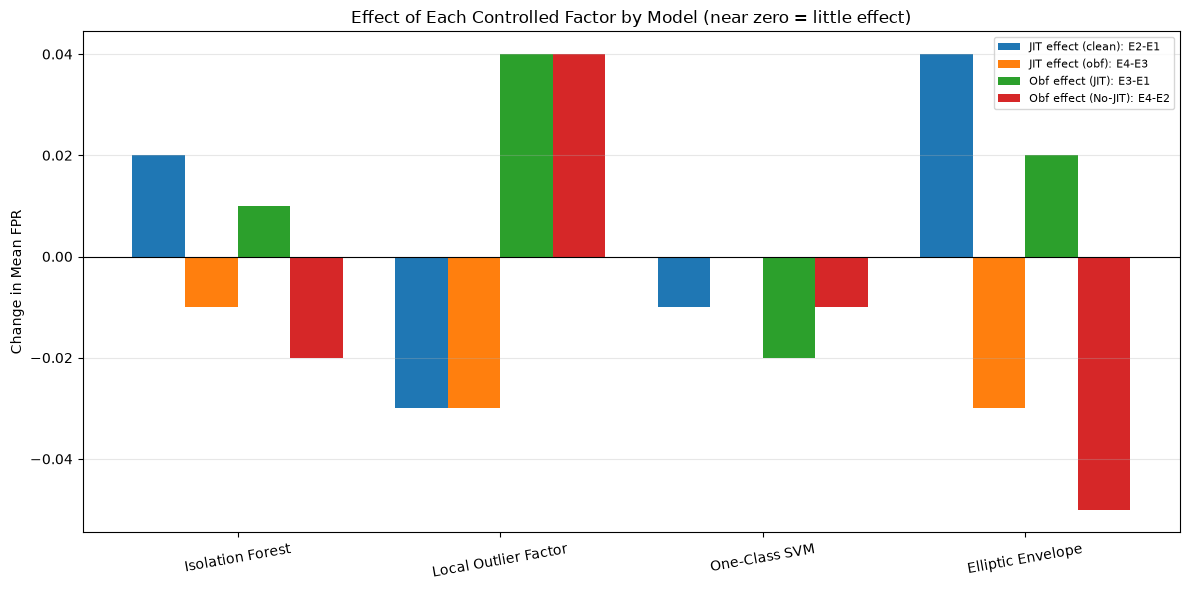

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))

effect_cols = list(factor_effects.columns)
x = np.arange(len(MODEL_ORDER))
bar_width = 0.2

# One bar per pairwise comparison grouped by model
for i, col in enumerate(effect_cols):
    ax.bar(x + i * bar_width, factor_effects[col].values, bar_width, label=col)

# Zero line - the closer a bar is to this, the less that factor changed the result
ax.axhline(0.0, color="black", linewidth=0.8)

ax.set_xticks(x + 1.5 * bar_width)
ax.set_xticklabels(MODEL_ORDER, rotation = 10)
ax.set_ylabel("Change in Mean FPR")
ax.set_title("Effect of Each Controlled Factor by Model (near zero = little effect)")
ax.legend(fontsize = 8)
ax.grid(axis = "y", alpha=0.3)

plt.tight_layout()
plt.show()

## Stability View - Mean Against Standard Deviation

This plot puts the two numbers that matter for a small dataset on the same axes. The horizontal axis is the mean false positive rate and the vertical axis is the standard deviation across folds. Every model in every environment is one point, coloured by model.

The best place to be is the bottom left corner which is a low mean and a low spread, meaning the model is both accurate and stable. The top right is the worst, a high error rate that also deviate a lot between folds. This view shows at 1st glance that the Isolation Forest and Local Outlier Factor points cluster in the good corner across all four environments. And the One-Class SVM and Elliptic Envelope points sit far out which supports ranking them as unsuitable rather than simply weaker.

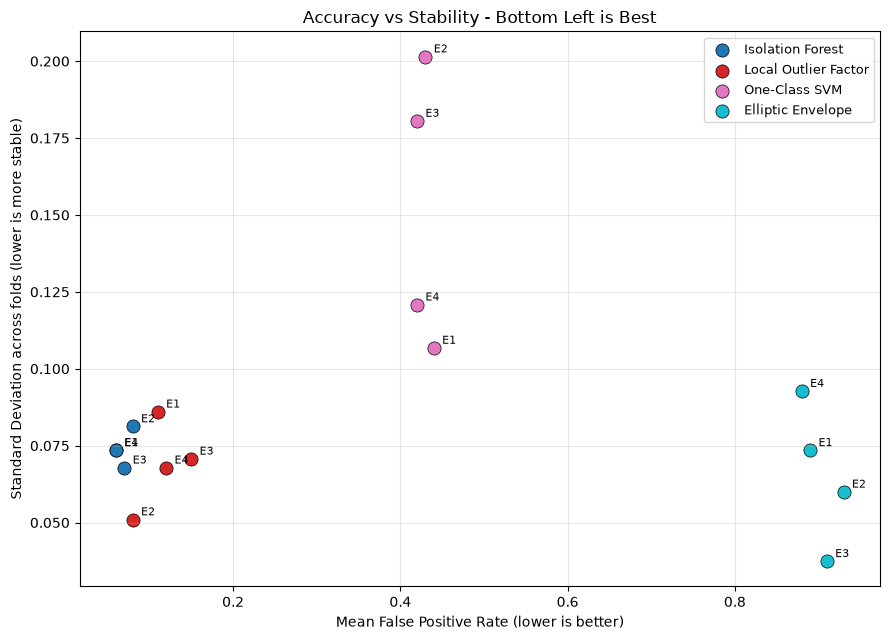

In [16]:
fig, ax = plt.subplots(figsize = (9, 6.5))

# One colour per model shared across all four of its environment points
colours = plt.cm.tab10(np.linspace(0, 1, len(MODEL_ORDER)))
colour_map = dict(zip(MODEL_ORDER, colours))

for model in MODEL_ORDER:
    model_rows = all_results[all_results["Model"] == model]
    ax.scatter(
        model_rows["Mean FPR"],
        model_rows["Std"],
        s = 90,
        color = colour_map[model],
        label = model,
        edgecolor = "black",
        linewidth = 0.5,
    )
    
    # Tag each point with its environment code so the four points can be told apart
    for _, row in model_rows.iterrows():
        ax.annotate(
            row["Environment"],
            (row["Mean FPR"], row["Std"]),
            textcoords="offset points",
            xytext = (6, 3),
            fontsize = 8,
        )

ax.set_xlabel("Mean False Positive Rate (lower is better)")
ax.set_ylabel("Standard Deviation across folds (lower is more stable)")
ax.set_title("Accuracy vs Stability - Bottom Left is Best")
ax.legend(fontsize = 9)
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

## Summary of the Cross Environment Findings

In [21]:
# Best model on average across all four environments (lowest mean of means)
avg_by_model = all_results.groupby("Model")["Mean FPR"].mean().loc[MODEL_ORDER]
best_model = avg_by_model.idxmin()

# Average size of each factor effect taken across both pairs and all models
jit_effect_mean = factor_effects[["JIT effect (clean): E2-E1", "JIT effect (obf): E4-E3"]].abs().mean().mean()
obf_effect_mean = factor_effects[["Obf effect (JIT): E3-E1", "Obf effect (No-JIT): E4-E2"]].abs().mean().mean()

print("Cross Environment Summary")
print("-" * 30)
print(f"\nBest Model Overall: {best_model} "
        f"(mean FPR {avg_by_model[best_model]:.3f} averaged across E1-E4)")

print(f"{best_model} FPR range across environments: "
        f"{iso_results['Mean FPR'].min():.3f} to {iso_results['Mean FPR'].max():.3f} "
        f"(spread {iso_spread:.3f})")

print(f"\nAverage Absolute JIT Effect: {jit_effect_mean:.3f}")
print(f"Average Absolute Obfuscation Effect: {obf_effect_mean:.3f}")

Cross Environment Summary
------------------------------

Best Model Overall: Isolation Forest (mean FPR 0.067 averaged across E1-E4)
Isolation Forest FPR range across environments: 0.060 to 0.080 (spread 0.020)

Average Absolute JIT Effect: 0.021
Average Absolute Obfuscation Effect: 0.026
